Escanea el mercado y trae los tickers cuyo precio este N% de su média móvil ponderada de 150 y 200 en SEMANAL.
Correr sábado o domingo: todas las barras son semanas cerradas

In [1]:
#Importa las librerias y módulos necesarios.
%load_ext autoreload
%autoreload 2
import pandas as pd
from datos import obtener_tickers

# Importa las librerias para gráficar.

import matplotlib.pyplot as plt
import math

In [2]:
# Descarga de datos semanales.

data_7d = obtener_tickers("1wk", "max")

Se han cargado 277 tickers...


$DFS: possibly delisted; no timezone found
$TEF: possibly delisted; no price data found  (1wk 1927-11-29 -> 2026-11-04)
$X: possibly delisted; no timezone found
$BK: possibly delisted; no price data found  (1wk 1927-11-29 -> 2026-11-04)

4 Failed downloads:
['DFS', 'X']: possibly delisted; no timezone found
['TEF', 'BK']: possibly delisted; no price data found  (1wk 1927-11-29 -> 2026-11-04)


Tiempo de descarga en 37.36 segundos.
Se descargó datos en temporalidad 1wk con un periodo de max


In [3]:
resultados = []

for ticker in data_7d.columns.get_level_values(0).unique():
    df_ticker = data_7d[ticker].dropna(subset=['Close', 'High', 'Low'])
    df_ticker = df_ticker.iloc[:-1]
    
    if len(df_ticker) >= 600:
        cierre = df_ticker['Close']
        high = df_ticker['High']
        
        s_ema_150 = cierre.ewm(span=150, adjust=False).mean()
        s_ema_200 = cierre.ewm(span=200, adjust=False).mean()
        
        ema_150 = s_ema_150.iloc[-1]
        ema_200 = s_ema_200.iloc[-1]
        precio = cierre.iloc[-1]

        # Validación estricta de pendiente a 14 periodos
        pendiente_150 = ema_150 > s_ema_150.iloc[-14]
        pendiente_200 = ema_200 > s_ema_200.iloc[-14]
        
        # Jerarquía alcista obligatoria: EMA 150 debe estar por encima de EMA 200
        estructura_valida = (ema_150 > ema_200)# and pendiente_150 and pendiente_200

        if estructura_valida:
            dist_150 = ((precio - ema_150) / ema_150) * 100
            dist_200 = ((precio - ema_200) / ema_200) * 100

            toque_150 = abs(dist_150) <= 1.0
            toque_200 = abs(dist_200) <= 1.0

            max_previo_150 = high.iloc[-8:-1].max() > (ema_150 * 1.03)
            max_previo_200 = high.iloc[-8:-1].max() > (ema_200 * 1.03)

            soportes_validos = (toque_150 and max_previo_150) or (toque_200 and max_previo_200)

            if soportes_validos:
                resultados.append({
                    'ticker': ticker,
                    'precio': precio,
                    'dist_150': dist_150,
                    'dist_200': dist_200,
                    'df_plot': df_ticker.iloc[-104:].copy()
                })

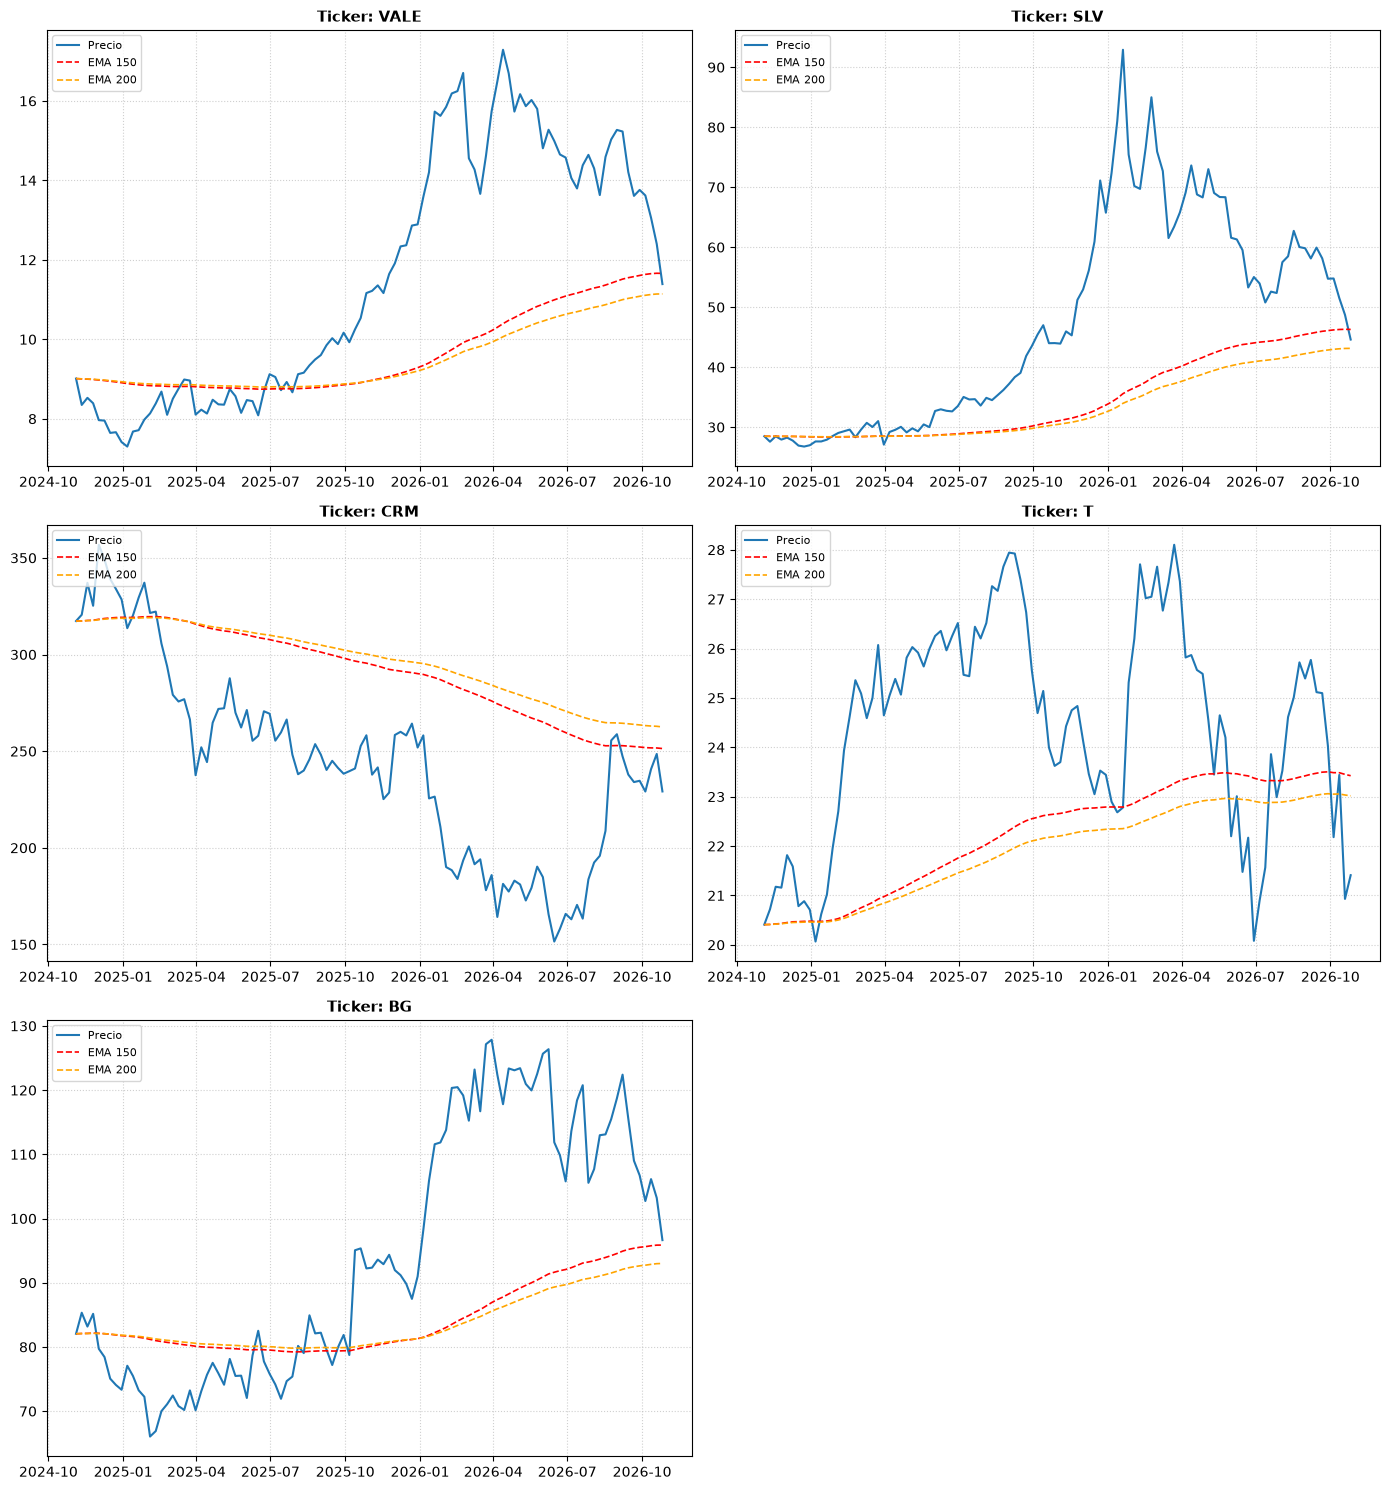

In [5]:
n_activos = len(resultados)
if n_activos > 0:
    cols = 2 if n_activos > 1 else 1
    rows = math.ceil(n_activos / cols)
    
    fig, axes = plt.subplots(rows, cols, figsize=(14, 5 * rows), squeeze=False)
    axes_flat = axes.flatten()
    
    for i, r in enumerate(resultados):
        ax = axes_flat[i]
        df_p = r['df_plot']
        c_p = df_p['Close']
        
        e150 = c_p.ewm(span=150, adjust=False).mean()
        e200 = c_p.ewm(span=200, adjust=False).mean()
        
        ax.plot(df_p.index, c_p, label='Precio', color='#1f77b4', linewidth=1.5)
        ax.plot(df_p.index, e150, label='EMA 150', color='red', linestyle='--', linewidth=1.2)
        ax.plot(df_p.index, e200, label='EMA 200', color='orange', linestyle='--', linewidth=1.2)
        
        ax.set_title(f"Ticker: {r['ticker']}", fontsize=11, fontweight='bold')
        ax.grid(True, linestyle=':', alpha=0.6)
        ax.legend(loc='upper left', fontsize=8)

    for j in range(i + 1, len(axes_flat)):
        fig.delaxes(axes_flat[j])
        
    plt.tight_layout()
    plt.show()
else:
    print("Sin activos válidos para graficar.")